# Discrete-Event Simulation: SimWeave vs SimPy

Companion notebook for the [SimWeave blog post](https://notabot123.github.io/simweave/blog/des-vs-simpy/).

Covers:
- **Machine shop** — reliable machines + repair centre, fleet availability
- **Monte Carlo** — availability distribution across 500 replicates
- **Warehouse extension** — spare parts, stock-outs, holding cost
- **Analytical optimisation** — Poisson heuristic and DE optimiser
- **Sensitivity sweep** — 2-D reorder-point cost heatmap

In [1]:
# Uncomment to install if running outside Binder
# !pip install 'simweave[viz,optim,ml]>=0.8.1' kaleido

import numpy as np
import simweave as sw
from simweave.reliability import (
    ReliableEntity, SubsystemSpec, RepairCentre,
    Fleet, FleetAvailabilityRecorder, sensitivity_sweep,
)
from simweave.supplychain import InventoryItems, Warehouse
from simweave.supplychain.optimization import (
    poisson_reorder_points, cost_optimise_stock,
)
from simweave.mc import run_monte_carlo
import plotly.graph_objects as go
import pathlib

IMG_DIR = pathlib.Path('img')
IMG_DIR.mkdir(exist_ok=True)

SIM_MINUTES = 4 * 60   # 240 minutes
N_MACHINES  = 10
MTTF        = 300.0    # mean time to failure (minutes)
MTTR        = 30.0     # mean repair time (minutes)

print('SimWeave', sw.__version__)

SimWeave 0.8.1


## 1  Machine Shop — Single Run

`ReliableEntity` always requires a `Warehouse` (it needs somewhere to source repair parts).
For a basic machine shop where parts are never constrained, we supply a minimal warehouse
with unlimited stock and instant replenishment — effectively transparent to the availability model.

In [2]:
machine_spec = SubsystemSpec(
    name='machine',
    failure_rate=1.0 / MTTF,
    repair_time=MTTR,
    consumable=False,
    sku_index=0,
    unit_cost=0.0,
)

def make_workshop_warehouse():
    '''Minimal warehouse — parts always available, no stock-out risk.'''
    inv = InventoryItems(
        part_names=['machine_part'],
        unit_cost=[0.0],
        stock_level=[1_000.0],
        batchsize=[500.0],
        reorder_points=[100.0],
        repairable_prc=[1.0],
        repair_times=[0.0],
        newbuy_leadtimes=[1.0],
    )
    return Warehouse(inventory=inv, name='workshop_store')


def build_shop(seed: int = 42):
    rng    = np.random.default_rng(seed)
    wh     = make_workshop_warehouse()
    repair = RepairCentre(capacity=1, buffer_size=50, name='repairman')
    macs   = [
        ReliableEntity(
            subsystems=[machine_spec],
            warehouse=wh,
            repair_centre=repair,
            rng=np.random.default_rng(rng.integers(0, 2**32)),
            name=f'machine_{i:02d}',
        )
        for i in range(N_MACHINES)
    ]
    fleet    = Fleet(macs, name='machine_fleet')
    recorder = FleetAvailabilityRecorder(fleet)

    env = sw.SimEnvironment(dt=1.0, end=SIM_MINUTES)
    env.register(wh)
    env.register(repair)
    for m in macs:
        env.register(m)
    env.register(recorder)
    return env, macs, fleet, recorder


env, machines, fleet, rec = build_shop(42)
env.run()

print(f'Fleet mean availability : {rec.mean_operational_availability:.2%}')
print()
print(f'{"Machine":14s}  {"Availability":>14s}  {"Downtime (min)":>15s}')
print('-' * 48)
for m in machines:
    avail = m.total_operational_time / SIM_MINUTES
    print(f'{m.name:14s}  {avail:>14.2%}  {m.total_downtime:>15.1f}')

Fleet mean availability : 82.79%

Machine           Availability   Downtime (min)
------------------------------------------------
machine_00              87.50%             30.0
machine_01              75.83%             58.0
machine_02             100.00%              0.0
machine_03              86.25%             33.0
machine_04              87.50%             30.0
machine_05              69.17%             74.0
machine_06              46.67%            128.0
machine_07              75.00%             60.0
machine_08             100.00%              0.0
machine_09             100.00%              0.0


## 2  Monte Carlo — Availability Distribution

500 replicates give us a distribution rather than a single-run point estimate.

In [3]:
def shop_scenario(seed: int) -> dict:
    rng    = np.random.default_rng(seed)
    wh     = make_workshop_warehouse()
    repair = RepairCentre(capacity=1, buffer_size=50)
    macs   = [
        ReliableEntity(
            subsystems=[machine_spec],
            warehouse=wh,
            repair_centre=repair,
            rng=np.random.default_rng(rng.integers(0, 2**32)),
        )
        for _ in range(N_MACHINES)
    ]
    fleet    = Fleet(macs)
    recorder = FleetAvailabilityRecorder(fleet)

    env = sw.SimEnvironment(dt=1.0, end=SIM_MINUTES)
    env.register(wh)
    env.register(repair)
    for m in macs:
        env.register(m)
    env.register(recorder)
    env.run()

    return {
        'mean_availability': recorder.mean_operational_availability,
        'total_downtime':    sum(m.total_downtime for m in macs),
    }


mc = run_monte_carlo(
    shop_scenario, n_runs=500,
    seeds=range(500),
    executor='threads',
)

avail = np.array([s['mean_availability'] for s in mc.samples])
print(f'Mean availability : {avail.mean():.2%}')
print(f'Std dev           : {avail.std():.2%}')
print(f'5th percentile    : {np.percentile(avail, 5):.2%}')
print(f'95th percentile   : {np.percentile(avail, 95):.2%}')

Mean availability : 86.26%
Std dev           : 7.75%
5th percentile    : 70.66%
95th percentile   : 95.79%


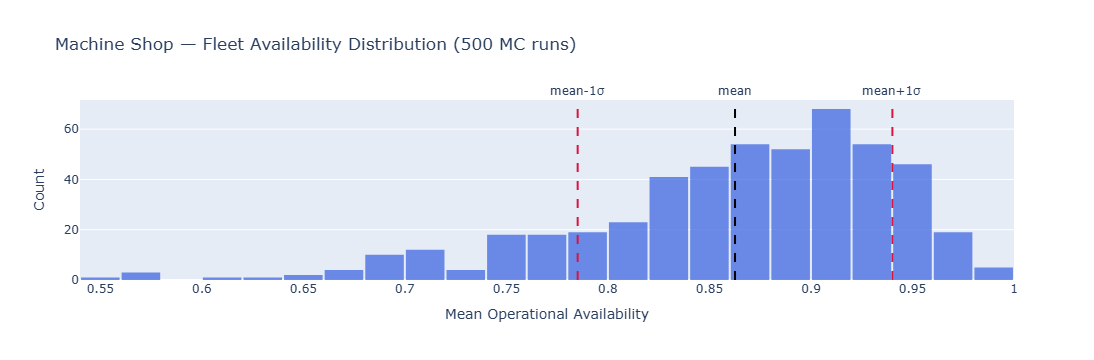

In [4]:
mu, sigma = avail.mean(), avail.std()

fig_hist = go.Figure()
fig_hist.add_trace(go.Histogram(
    x=avail, nbinsx=40, name='replications',
    marker_color='royalblue', opacity=0.75,
))
for x, label, color in [
    (mu,         'mean',    'black'),
    (mu - sigma, 'mean-1σ', 'crimson'),
    (mu + sigma, 'mean+1σ', 'crimson'),
]:
    fig_hist.add_vline(x=x, line_color=color, line_dash='dash',
                       annotation_text=label, annotation_position='top')
fig_hist.update_layout(
    title='Machine Shop — Fleet Availability Distribution (500 MC runs)',
    xaxis_title='Mean Operational Availability',
    yaxis_title='Count',
    bargap=0.05,
)
fig_hist.show()
fig_hist.write_image(str(IMG_DIR / 'shop_mc_histogram.png'), width=900, height=500, scale=2)

## 3  Adding a Warehouse — Spare Parts and Stock-Outs

Now we use a *real* warehouse with finite stock, reorder policies, and lead times.
When a part is unavailable the machine must wait — additional downtime accrues.

In [5]:
SKU_SPINDLE, SKU_MOTOR, SKU_BEARING, SKU_SEAL = 0, 1, 2, 3

spindle_spec = SubsystemSpec(
    name='spindle', failure_rate=1/150, sku_index=SKU_SPINDLE,
    consumable=False, repair_time=7.0, unit_cost=5_000.0,
    beyond_economic_repair_prc=0.20,
)
motor_spec = SubsystemSpec(
    name='motor', failure_rate=1/200, sku_index=SKU_MOTOR,
    consumable=False, repair_time=3.0, unit_cost=2_200.0,
    beyond_economic_repair_prc=0.10,
)
bearing_spec = SubsystemSpec(
    name='bearing', failure_rate=1/80, sku_index=SKU_BEARING,
    consumable=False, repair_time=2.0, unit_cost=1_200.0,
    beyond_economic_repair_prc=0.05,
)
seal_spec = SubsystemSpec(
    name='seal', failure_rate=1/50, sku_index=SKU_SEAL,
    consumable=True, repair_time=0.5, unit_cost=300.0,
    beyond_economic_repair_prc=0.0,
)

ALL_SPECS = [spindle_spec, motor_spec, bearing_spec, seal_spec]


def make_parts_warehouse(reorder_spindle: float = 2.0,
                          reorder_motor:   float = 2.0,
                          reorder_bearing: float = 3.0,
                          reorder_seal:    float = 5.0) -> Warehouse:
    inv = InventoryItems(
        part_names=['spindle', 'motor', 'bearing', 'seal'],
        unit_cost=[5_000.0, 2_200.0, 1_200.0, 300.0],
        stock_level=[4.0, 6.0, 8.0, 15.0],
        batchsize=[2.0, 2.0, 4.0, 10.0],
        reorder_points=[reorder_spindle, reorder_motor, reorder_bearing, reorder_seal],
        repairable_prc=[0.80, 0.90, 0.95, 0.0],
        repair_times=[7.0, 3.0, 2.0, 0.5],
        newbuy_leadtimes=[21.0, 14.0, 7.0, 3.0],
    )
    return Warehouse(inventory=inv, name='parts_store')


def warehouse_cost(wh: Warehouse) -> float:
    '''Total procurement cost: lifetime orders placed × unit cost per SKU.'''
    return float(np.dot(wh._lifetime_total_orders, wh.inv.unit_cost))


# Single run with all four parts
rng0  = np.random.default_rng(0)
wh    = make_parts_warehouse()
rc    = RepairCentre(capacity=2, buffer_size=50)
macs  = [
    ReliableEntity(
        subsystems=ALL_SPECS, warehouse=wh, repair_centre=rc,
        rng=np.random.default_rng(rng0.integers(0, 2**32)),
    )
    for _ in range(N_MACHINES)
]
fleet2    = Fleet(macs)
recorder2 = FleetAvailabilityRecorder(fleet2)

env2 = sw.SimEnvironment(dt=1.0, end=365)
env2.register(wh)
env2.register(rc)
for m in macs:
    env2.register(m)
env2.register(recorder2)
env2.run()

print(f'Mean availability (with warehouse) : {recorder2.mean_operational_availability:.2%}')
print(f'Warehouse total cost               : £{warehouse_cost(wh):,.0f}')

Mean availability (with warehouse) : 87.81%
Warehouse total cost               : £88,300


## 4  Analytical Steady-State Optimisation

If mean demand rates are known, the Poisson heuristic and DE optimiser find
near-optimal reorder points without running any simulation.

In [9]:
# Attach fleet-level demand rates (failures per day) for all four SKUs
wh._demand_rate = np.array([
    (1.0 / 150) * N_MACHINES,   # spindle
    (1.0 / 200) * N_MACHINES,   # motor
    (1.0 / 80)  * N_MACHINES,   # bearing
    (1.0 / 50)  * N_MACHINES,   # seal
])

k_poisson, cost_p = poisson_reorder_points(wh, target_availability=0.90)
k_de,      cost_de = cost_optimise_stock(wh,  target_availability=0.90, maxiter=150)

print('Target service level : 90%')
print(f'Poisson heuristic  : reorder at {k_poisson}  cost £{cost_p:,.0f}')
print(f'DE optimiser       : reorder at {k_de}  cost £{cost_de:,.0f}')
if cost_p > 0:
    print(f'Saving             : £{max(0, cost_p - cost_de):,.0f}  ({100*max(0,1-cost_de/cost_p):.1f}%)')

# Store bearing/seal optimal points for the sensitivity sweep below
# (sweep only over the two expensive parts; hold the cheaper ones at their optimum)
r_bearing_opt = float(k_poisson[2])
r_seal_opt    = float(k_poisson[3])

Target service level : 90%
Poisson heuristic  : reorder at [3. 1. 2. 2.]  cost £42,400
DE optimiser       : reorder at [2. 1. 1. 2.]  cost £36,200
Saving             : £6,200  (14.6%)


venv\Lib\site-packages\scipy\optimize\_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
venv\Lib\site-packages\scipy\optimize\_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


### Pareto Front — Cost vs Target Availability

With four parts to optimise, a full grid sweep is impractical (it would require a 4-D heatmap).
The Poisson heuristic gives us an instant solution for any target — so we can sweep targets from
50 % to 99 % and trace the **cost–availability Pareto front** in seconds.

> **Coming in v0.9:** `simweave.supplychain.optimization` will expose a `pareto_availability_curve()`
> helper that wraps this loop, supports DataFrame initialisation of `InventoryItems`, and
> adds warehouse `total_cost` as a first-class property.

In [23]:
def plot_pareto_sweep(
    warehouse: Warehouse,
    availability_range: np.ndarray | None = None,
    *,
    theme: str | None = None,
    title: str | None = None,
) -> Any:
    """Plot cost vs availability with optional DE and Poisson curves.

    Parameters
    ----------
    warehouse:
        Warehouse instance to optimise.
    availability_range:
        Optional array of availability targets.
    theme:
        Optional Plotly theme.
    title:
        Optional plot title.
    """
    go = _plotly.require_go()

    sweep = pareto_sweep(warehouse, availability_range)
    a = sweep["availability"]

    fig = go.Figure()

    # Poisson heuristic
    if "cost_poisson" in sweep:
        c_p = sweep["cost_poisson"]
        fig.add_trace(
            go.Scatter(
                x=c_p,
                y=a,
                mode="lines+markers",
                name="Poisson heuristic",
                line={"dash": "dash", "width": 2},
            )
        )

    # DE cost-optimal
    if "cost_cost_optimal" in sweep:
        c_de = sweep["cost_cost_optimal"]
        fig.add_trace(
            go.Scatter(
                x=c_de,
                y=a,
                mode="lines+markers",
                name="cost-optimal (DE)",
                line={"width": 2},
            )
        )

        # Shaded savings region (only if Poisson also present)
        if "cost_poisson" in sweep:
            fig.add_trace(
                go.Scatter(
                    x=np.concatenate([c_p, c_de[::-1]]),
                    y=np.concatenate([a, a[::-1]]),
                    fill="toself",
                    fillcolor="rgba(0, 150, 0, 0.1)",
                    line={"width": 0},
                    name="savings region",
                    hoverinfo="skip",
                    showlegend=True,
                )
            )

    wname = getattr(warehouse, "name", "warehouse")

    fig.update_layout(
        title=title or f"cost vs availability: {wname}",
        xaxis_title="total cost",
        yaxis_title="target availability",
        legend_title_text="method",
    )

    return apply_theme(fig, theme)


venv\Lib\site-packages\scipy\optimize\_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
venv\Lib\site-packages\scipy\optimize\_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


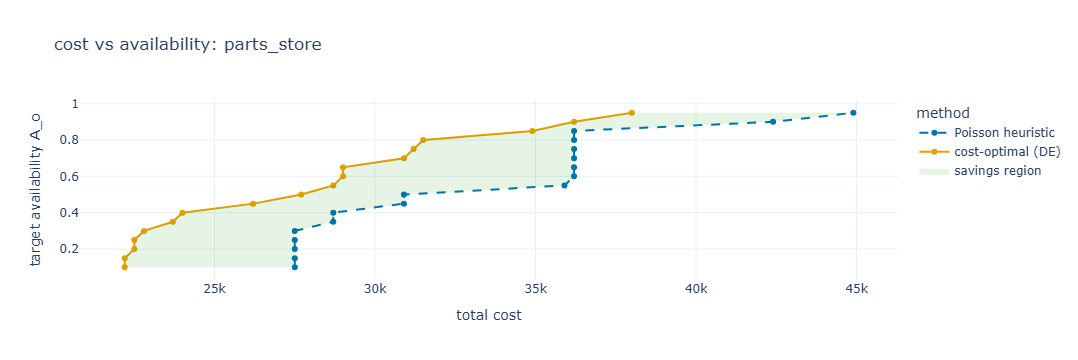

In [24]:
plot_pareto_sweep(wh)

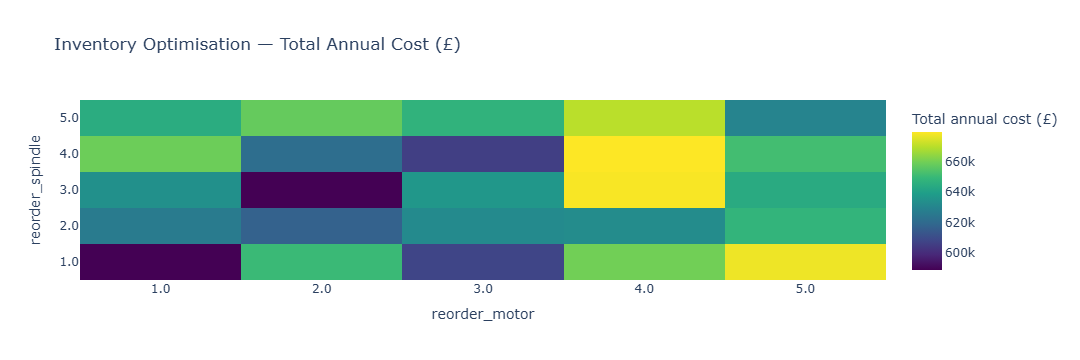

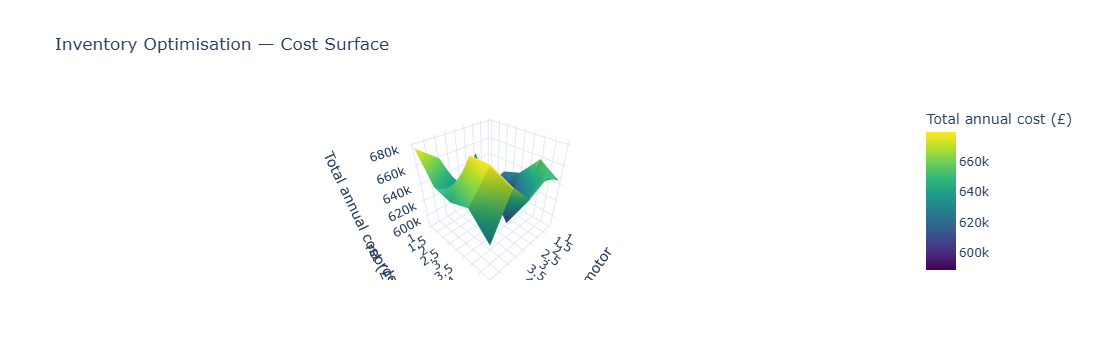

In [7]:
DOWNTIME_COST_PER_DAY = 50.0 * 24   # £ per machine per day idle

# Sweep spindle and motor reorder points; hold bearing and seal at their Poisson optima.
# A full 4-D grid would be ~5^4 = 625 cells × 15 MC runs = 9 375 simulations — impractical.
# Fixing the cheaper, faster-moving parts at their analytical optimum is a common
# industrial heuristic; the expensive long-lead parts drive most of the cost variance.
def shop_cost(reorder_spindle: float, reorder_motor: float, seed: int) -> float:
    rng  = np.random.default_rng(seed)
    wh   = make_parts_warehouse(reorder_spindle, reorder_motor,
                                 r_bearing_opt, r_seal_opt)
    rc   = RepairCentre(capacity=2, buffer_size=50)
    macs = [
        ReliableEntity(
            subsystems=ALL_SPECS,
            warehouse=wh,
            repair_centre=rc,
            rng=np.random.default_rng(rng.integers(0, 2**32)),
        )
        for _ in range(N_MACHINES)
    ]
    env = sw.SimEnvironment(dt=1.0, end=365)
    env.register(wh)
    env.register(rc)
    for m in macs:
        env.register(m)
    env.run()
    downtime_cost = sum(m.total_downtime for m in macs) * DOWNTIME_COST_PER_DAY
    return warehouse_cost(wh) + downtime_cost


sweep = sensitivity_sweep(
    shop_cost,
    param1_name='reorder_spindle',  param1_values=[1, 2, 3, 4, 5],
    param2_name='reorder_motor',    param2_values=[1, 2, 3, 4, 5],
    metric_name='Total annual cost (£)',
    n_runs=15,
    seed=0,
)

fig_hm = sw.plot_sensitivity_surface(
    sweep, chart_type='heatmap',
    title='Inventory Optimisation — Total Annual Cost (£)',
)
fig_hm.show()
fig_hm.write_image(str(IMG_DIR / 'inventory_heatmap.png'), width=700, height=600, scale=2)

fig_surf = sw.plot_sensitivity_surface(
    sweep, chart_type='surface',
    title='Inventory Optimisation — Cost Surface',
)
fig_surf.show()
fig_surf.write_image(str(IMG_DIR / 'inventory_surface.png'), width=800, height=600, scale=2)

## Summary — Exported Images

| File | Description |
|---|---|
| `shop_mc_histogram.png` | Fleet availability distribution across 500 MC runs |
| `inventory_pareto.png` | Cost vs target availability Pareto front (4-SKU fleet) |
| `inventory_heatmap.png` | Total annual cost heatmap — spindle vs motor reorder points |
| `inventory_surface.png` | 3-D cost surface |